In [1]:
import warnings
from typing import Any, Literal

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor as RF
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from utils import plot_time_series

%load_ext autoreload
%autoreload 2
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)

# Table of Contents
1. [Preparing baseline data](#Preparing-baseline-data)
2. [Linear Model Baseline](#Linear-Model-Baseline)
3. [Random Forest Baseline](#Random-Forest-Baseline)
4. [Linear vs Random Forest Baseline Conclusion](#Linear-vs-Random-Forest-Baseline-Conclusion)
4. [Data Cleaning](#Data-Cleaning)
5. [Analysis of RF predictions](#Analysis-of-RF-predictions)
6. [Feature Engineering: Lagged features including Target](#Feature-Engineering:-Lagged-features-including-Target)
7. [Feature Engineering: Lagged WITHOUT including Target](#Feature-Engineering:-Lagged-features-WITHOUT-Target)
8. [Statistical rolling features](#Statistical-rolling-features)
9. [Treating Regression Error as Anomaly](#Treating-Regression-Error-as-Anomaly)
10. [Conclusions](#Conclusions)

# Preparing baseline data

In [2]:
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
SEED = 42
df.columns

Index(['WindSpeed', 'WindDirAbs', 'WindDirRel', 'Power', 'Pitch', 'GenRPM',
       'RotorRPM', 'EnvirTemp', 'NacelTemp', 'GearOilTemp', 'GearBearTemp',
       'GenPh1Temp', 'GenBearTemp'],
      dtype='object')

So, during the initial EDA analysis, we have decided that out first approach to detect anomaly will be predicting Power using an ML model and then computing the error between the prediction and the true values.

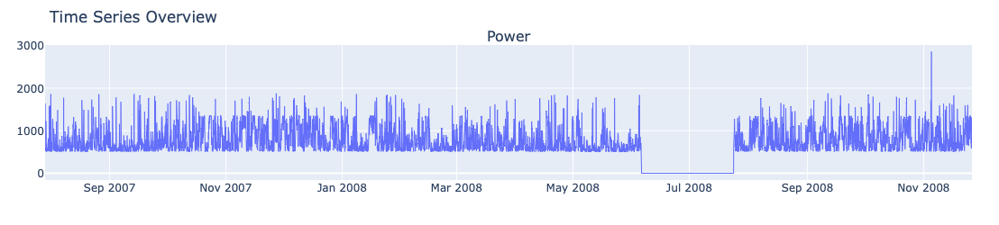

In [3]:
plot_time_series(df, ["Power"], step=2)

After clear data understanding, it's a good practice to create a baseline model and check what kind of performance we can expect if we use pure raw data and simple models without any tuning.

It also helps us to understand the level of data cleaning and feature engineering we likely need to do.

**Drop the downtime**

There is no point using downtime in the dataset, so we just skip it.

In [4]:
df = df[df["Power"] > 20].copy()

In [5]:
df.head(3)

,WindSpeed,WindDirAbs,WindDirRel,Power,Pitch,GenRPM,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenPh1Temp,GenBearTemp
Timestamps,,,,,,,,,,,,,
2007-07-29 03:10:00,4.790142,307.5,1.8,520.300000,-1.483813,1078.376427,16.229237,17.866438,59.882623,58.059329,49.079118,79.193312,51.0
2007-07-29 03:20:00,4.285207,312.5,2.2,564.700000,1.831067,841.497573,16.686210,21.404675,15.233595,46.598905,45.249571,95.670331,52.0
2007-07-29 03:30:00,7.143066,304.4,-4.9,1632.407112,-4.402055,1022.534164,15.149165,16.315175,30.932959,49.956838,55.738552,102.969851,53.0


In [6]:
df.shape

(63000, 13)

What we will do is that we split the dataset into the train and test part.

The train part will be considered as "NORMAL".

This means that we assume that there are no anomalies in that region.

Then the idea is that if the deviation of the measured Power values from the predictions are high, then this indicates that this region is likely to be an anomaly because it's drifting from the "NORMAL" training data.

We will take the first 30k points as training data. This value can be selected different but it seems to be a good compromise between having enough data from training and being far enough from the downtime where we observed the anomaly happens (which makes sense).

In [7]:
def get_datasets(df: pd.DataFrame, target: str, split_index=30_000) -> tuple:
    """
    Prepares train and test datasets
    """
    # Split based on the split_index
    df_train = df[:split_index].copy()
    df_test = df[split_index:].copy()

    # Splitting x and y
    x_train, y_train = df_train.drop(columns=[target]), df_train[target]
    x_test, y_test = df_test.drop(columns=[target]), df_test[target]

    return (x_train, y_train, x_test, y_test)

In [8]:
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power", 30_000)

Text(0, 0.5, 'Power')

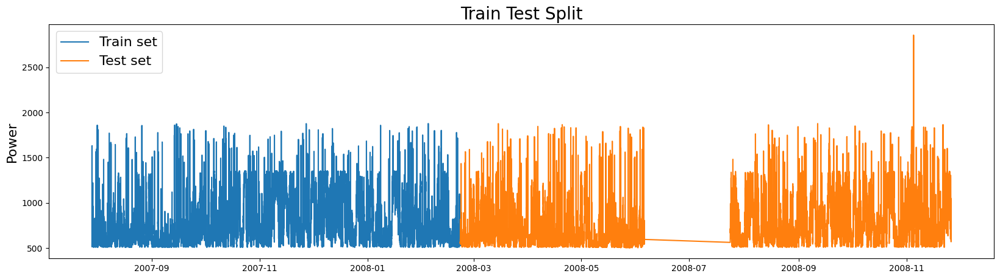

In [9]:
plt.figure(figsize=(20, 5))
plt.plot(y_train, label="Train set")
plt.plot(y_test, label="Test set")
plt.legend(fontsize=16)
plt.title("Train Test Split", fontsize=20)
plt.ylabel("Power", fontsize=16)

**Metrics**

For time series, it's a golden rule that for the validation/test sets we take values from the future, so we never should split data randomly.

During training and validation, we split the training set to 3 validation folds using Sliding Time Series Cross Validation. 

So, we always training on the past data and validation on the future data.

We then compute both cross validation errors and the test set errors.

For the metrics, we will use MAE, RMSE and MAPE error to have different views and decide which main metric wil will use later one.

In [10]:
def compute_metrics(
    y_true: np.ndarray, y_pred: np.ndarray
) -> tuple[float, float, float]:
    """
    Compute MAE, RMSE, and MAPE for regression predictions.

    Parameters
    ----------
    y_true : array-like
        Ground truth values.
    y_pred : array-like
        Predicted values.

    Returns
    -------
    tuple of floats
        (mae, rmse, mape)
    """
    # Make 1D arrays. Critical to have the arrays of the same shape
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()

    # Metrics
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = (
        np.mean(np.abs((y_true - y_pred) / np.clip(np.abs(y_true), 1e-8, None))) * 100
    )
    return mae, rmse, mape

It's a good practice to prepare a function that evaluates the model to which we give the required inputs and as the output, we get the metrics.

It saves a lot of space, time and errors along the Notebook.

In [11]:
def eval_model(
    x_train: pd.DataFrame,
    y_train: pd.Series,
    x_test: pd.DataFrame,
    y_test: pd.Series,
    n_splits: int = 3,
    model_name: Literal["RF", "LinReg"] = "RF",
    model_params: dict[str, Any] | None = None,
) -> dict[str, Any]:
    """
    Evaluate a time series model using TimeSeriesSplit cross-validation
    on the training set, then refit on the full train data and evaluate on test.
    """
    np.random.seed(SEED)

    if model_params is None:
        model_params = {}

    tscv = TimeSeriesSplit(n_splits=n_splits)
    cv_mae_list: list[float] = []
    cv_rmse_list: list[float] = []
    cv_mape_list: list[float] = []

    # --- Time Slidong Window Cross-validation ---
    for fold, (train_idx, val_idx) in enumerate(tscv.split(x_train), 1):
        # Select training and validation data
        x_train_cv = x_train.iloc[train_idx, :].copy()
        x_val_cv = x_train.iloc[val_idx, :].copy()
        y_train_cv = y_train.iloc[train_idx].copy().values.ravel()
        y_val_cv = y_train.iloc[val_idx].copy().values.ravel()

        # Scaling
        x_scaler = StandardScaler()
        x_scaled_cv_train = x_scaler.fit_transform(x_train_cv)
        x_scaled_cv_val = x_scaler.transform(x_val_cv)

        if model_name == "RF":
            model = RF(**model_params)
        elif model_name == "LinReg":
            model = Ridge(**model_params)
        else:
            raise ValueError(f"Unknown model_name: {model_name}")

        # Training and predictions
        model.fit(x_scaled_cv_train, y_train_cv)
        y_pred_cv = model.predict(x_scaled_cv_val)

        # Computing metrics
        mae_err, rmse_err, mape_err = compute_metrics(y_val_cv, y_pred_cv)
        cv_mae_list.append(float(mae_err))
        cv_rmse_list.append(float(rmse_err))
        cv_mape_list.append(float(mape_err))

    # Compute mean errors
    cv_mae = float(np.mean(cv_mae_list))
    cv_rmse = float(np.mean(cv_rmse_list))
    cv_mape = float(np.mean(cv_mape_list))

    # Final model re-training on the whole training set
    if model_name == "RF":
        model = RF(**model_params)
    elif model_name == "LinReg":
        model = Ridge(**model_params)
    else:
        raise ValueError(f"Unknown model_name: {model_name}")

    # Scaling
    x_scaler = StandardScaler()
    x_scaled_train = x_scaler.fit_transform(x_train)
    x_scaled_test = x_scaler.transform(x_test)

    # Fitting, predictin, computing errors
    model.fit(x_scaled_train, y_train.values.ravel())
    y_pred_test = model.predict(x_scaled_test)
    mae_err_test, rmse_err_test, mape_err_test = compute_metrics(y_test, y_pred_test)

    return {
        "cv_mae": round(cv_mae, 2),
        "cv_rmse": round(cv_rmse, 2),
        "cv_mape": round(cv_mape, 2),
        "test_mae": round(float(mae_err_test), 2),
        "test_rmse": round(float(rmse_err_test), 2),
        "test_mape": round(float(mape_err_test), 2),
        "y_pred_test": y_pred_test,
        "model": model,
    }

# Linear Model Baseline

First, we start with the simpliest model possible - Linear Model. 

If this model well, it would be a great baseline and maybe even a production model.  Let's see!

**PRO TIP**: don't make a mistake of fitting complex models like LSTMs, Transformers, etc in the beginning. First, **always** understand how simplier models perform and go to more complex alternatives only after that.

In [12]:
# Get data
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power", 30_000)

# Set params
params = {"alpha": 0}

eval_results = eval_model(x_train, y_train, x_test, y_test, 3, "LinReg", params)
eval_results

{'cv_mae': 95.57,
 'cv_rmse': 139.35,
 'cv_mape': 11.09,
 'test_mae': 95.23,
 'test_rmse': 137.0,
 'test_mape': 12.98,
 'y_pred_test': array([564.35800131, 613.36188892, 581.36451227, ..., 782.8785422 ,
        706.28896314, 679.67473719]),
 'model': Ridge(alpha=0)}

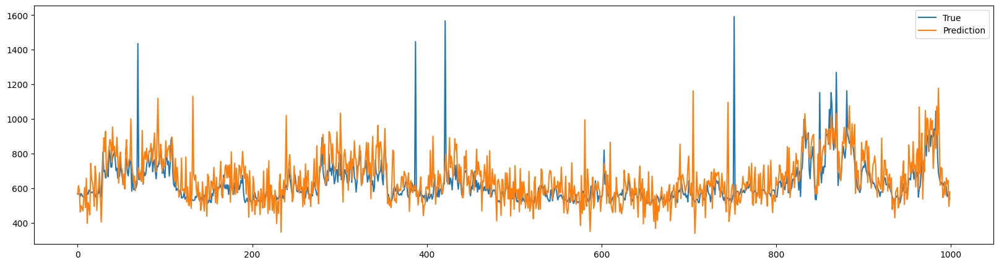

In [13]:
plt.figure(figsize=(20, 5))
plt.plot(y_test.values[:1000], label="True")
plt.plot(eval_results["y_pred_test"][:1000], label="Prediction")
plt.legend()

- In general, the predictions do not look good. The model seems to overfit and having high prediction variance (high fluctuations).
- Also, as we already have seen in EDA, our target has outliers, so it can be a big problem, especially for a linear model.
- Also, our target does not follow a Normal distribution which can be a big problem for linear regression models.
- ALWAYS, to make better conclusions, zoom in. Let's do with Plotly.

In [14]:
def plot_predictions(y_true: pd.Series, y_pred: pd.Series, title: str) -> None:
    """
    Plots interactive predictions with Plotly
    """
    # Assume y_test and y_pred are pandas Series with a datetime index
    fig = go.Figure()

    # Add actual values
    fig.add_trace(
        go.Scatter(
            x=y_true.index,
            y=y_true.values,
            mode="lines",
            name="Actual",
            line=dict(width=2),
        )
    )

    # Add predicted values
    fig.add_trace(
        go.Scatter(
            x=y_true.index, y=y_pred, mode="lines", name="Predicted", line=dict(width=1)
        )
    )

    # Customize layout
    fig.update_layout(
        title=title,
        xaxis_title="Date",
        yaxis_title="Value",
        legend=dict(x=0, y=1),
        height=500,
    )

    fig.show()

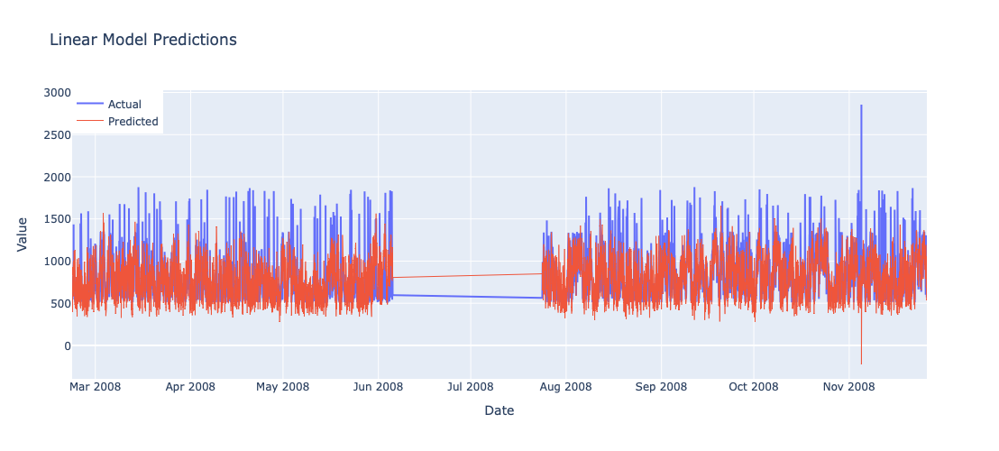

In [15]:
plot_predictions(y_test, eval_results["y_pred_test"], "Linear Model Predictions")

Let's try to add some regularization.

In [16]:
# Get data
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power", 30_000)

# Set params
params = {"alpha": 10}

eval_results = eval_model(x_train, y_train, x_test, y_test, 3, "LinReg", params)
eval_results

{'cv_mae': 95.59,
 'cv_rmse': 139.38,
 'cv_mape': 11.1,
 'test_mae': 95.23,
 'test_rmse': 137.0,
 'test_mape': 12.98,
 'y_pred_test': array([564.39489091, 613.38975905, 581.39283681, ..., 782.90898264,
        706.35585535, 679.64713239]),
 'model': Ridge(alpha=10)}

We see that adding regularization does not help much (same errors as before with alpha=0)

It seems that with such noisy but dense data, it will be hard to fit a linear model, at least, without an extensive cleaning.

It can also be the case that our problem is non-linear.

This actually makes sense because we saw visually and even during PCA, the first 2 components did not explain even 80% of the variance which also indicates the problem non-linearity.

To make a quick comparison, let's fit a non-linear model, e.g. Random Forest.

# Random Forest Baseline

In [17]:
# Get data
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power", 30_000)

params = {"n_estimators": 100, "random_state": SEED, "n_jobs": -1}

eval_results = eval_model(x_train, y_train, x_test, y_test, 3, "RF", params)
eval_results

{'cv_mae': 70.05,
 'cv_rmse': 113.39,
 'cv_mape': 8.16,
 'test_mae': 74.57,
 'test_rmse': 122.68,
 'test_mape': 9.77,
 'y_pred_test': array([565.52      , 628.36746567, 551.576     , ..., 741.092     ,
        607.77384346, 687.445     ]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [30]:
# Linear model errors
# 'cv_mae': 95.59,
#  'cv_rmse': 139.38,
#  'cv_mape': 11.1,
#  'test_mae': 95.23,
#  'test_rmse': 137.0,
#  'test_mape': 12.98,

We see a sudden improvement. That's great! Let's see what the predictions look like.

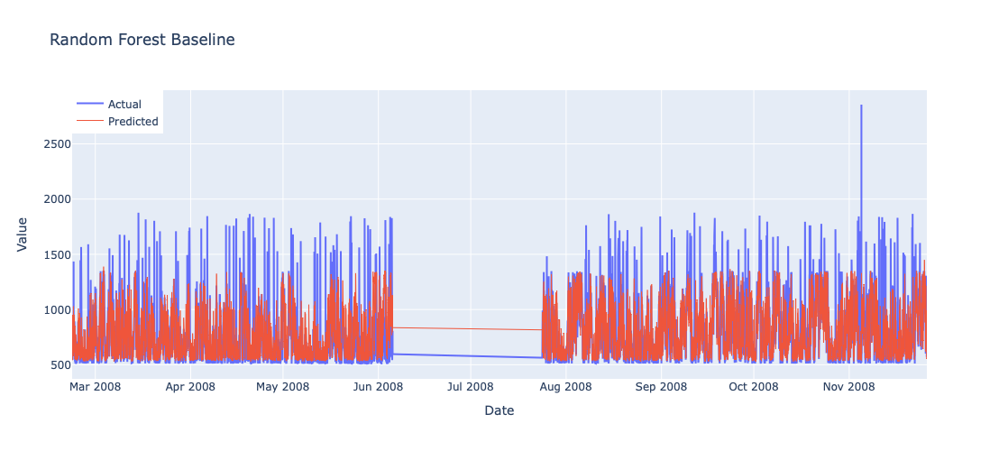

In [18]:
plot_predictions(y_test, eval_results["y_pred_test"], "Random Forest Baseline")

We still see high variance but the predictions are way more stable now.

Also, we can easily see that the predictions do not go below the lowest true values but the linear model did not manage to do that.

Let's also check how the built-in feature importance looks like.

In [19]:
# Extract values
importances = eval_results["model"].feature_importances_
cols = x_train.columns

# Combine into DataFrame
feat_imp = (
    pd.DataFrame({"feature": cols, "importance": importances})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

feat_imp

,feature,importance
0,GenRPM,0.663157
1,GenPh1Temp,0.165117
2,WindSpeed,0.033611
3,Pitch,0.032618
4,RotorRPM,0.017246
5,GearOilTemp,0.015171
6,GearBearTemp,0.014157
7,WindDirAbs,0.012938
8,NacelTemp,0.012280
9,GenBearTemp,0.011804


Among the TOP 2 features, we see the same ones that we observed in our EDA analysis.

We also see that many features are WAY less important. Let's keep it in mind for further modelling.

### ⚠️ Notes on Random Forest Feature Importance:

1. **Computed only on the training set**  
   Can overstate importance due to overfitting.

2. **Biased toward high-cardinality features**  
   Continuous or many-unique-value features appear more important.

3. **Not causal, only predictive**  
   Importance ≠ real-world influence.

**So, essentially it explains how the model fits the training data, it does NOT explain causality.**

# Linear vs Random Forest Baseline Conclusion

Among the two baselines, it's obvious we need to go with Random Forest and explore it further because:
- It has smaller errors
- It has smaller prediction variance
- It doesn't produce values below the low limit like Linear Regression.
- It's more robust to noise and non-normality of the target.

We also see that the spikes are not predicted which is a good sign - the model does not get overfitted (it could be different in case of Gradient Boosting or Neural Network, for example).

However, in EDA we saw that features and the target itself have outliers which can negatively impact the model accuracy.

Let's see if basic outlier removal would help.

# Data Cleaning

First, it's crucial to deal with outliers in target.

In general, by properly cleaning the target, we can achieve one of the highest boosts in model performance.

This is especially the case in this problem, because measurements are very noisy and have many outliers.

## Removing Outliers in target

For quick iterations between different experiments, it's better to read the data again in each section.

This reduces a change to operate with the dataframe that has already been modified.

In [20]:
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
df = df[df["Power"] > 20].copy()

In [21]:
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power")

(0.0, 20.0)

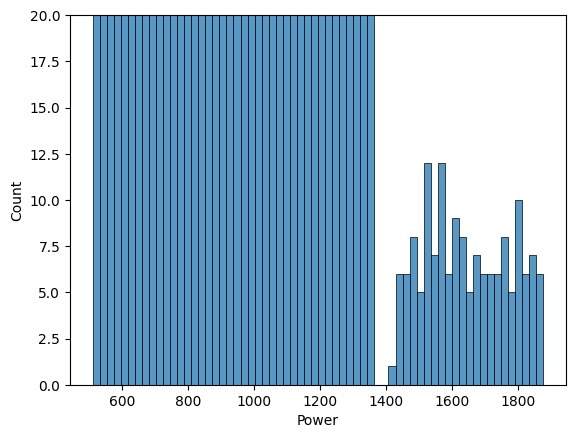

In [22]:
sns.histplot(y_train)
plt.ylim(0, 20)

We clearly see that there are outliers. Let's remove them using z-score filtering. 

Again, we start from the simpliest method. 

Text(0.5, 1.0, 'Z-score of Power data')

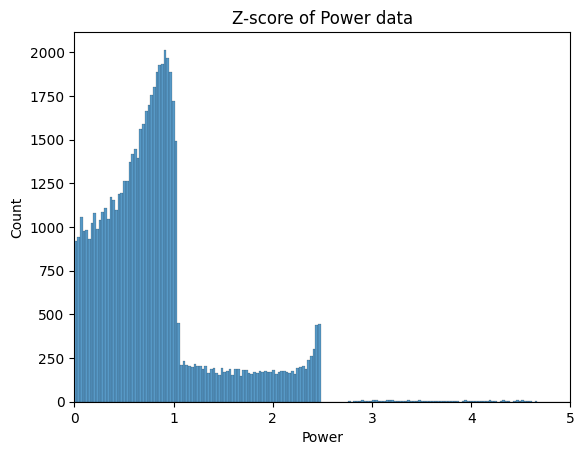

In [23]:
# Z-score visualization
mean = df["Power"].mean()
std = df["Power"].std(ddof=0)
z_score = np.abs((df["Power"] - mean) / std)
sns.histplot(z_score)
plt.xlim(0, 5)
plt.title("Z-score of Power data")

In [24]:
def remove_outliers_zscore(
    df: pd.DataFrame,
    threshold: float = 3.0,
    nan_treatment: str = "ffill",
    stats: dict[str, tuple[float, float]] | None = None,
) -> tuple[pd.DataFrame, dict[str, tuple[float, float]]]:
    """
    Replace outliers (per-column z-score > threshold) with NaN.
    Optionally forward-fills or drops the resulting NaNs.
    If stats are provided, uses them; otherwise computes and returns them
    (so the same parameters can be applied to test data).

    Parameters
    ----------
    df : pd.DataFrame
        Input data (numeric/mixed).
    threshold : float
        |z| cutoff.
    nan_treatment : {'ffill','drop'}
        How to handle NaNs.
    stats : dict or None
        Precomputed statistics {col: (mean, std)}.

    Returns
    -------
    df_masked : pd.DataFrame
        DataFrame with outliers replaced and NaN treatment applied.
    fit_stats : Dict[str,(float,float)]
        Mean and std used (save for test).
    """

    df_masked = df.copy()
    fit_stats = {}

    # If we don't have pre-computed statistics, we compute it.
    # Pre-computed values on the train set can be used on the test set
    if stats is None:
        for col in df.columns:
            fit_stats[col] = (df[col].mean(), df[col].std(ddof=0))
    else:
        fit_stats = stats

    total_changed = 0

    for col in df.columns:
        # Compute statistics
        mean, std = fit_stats[col]
        if std == 0:
            # We skip because we cannot divide by zero
            print(f"{col}: std==0, skipped")
            continue

        # Compute the z-score
        z = np.abs((df[col] - mean) / std)
        changed = int((z > threshold).sum())
        total_changed += changed

        print(f"{col}: {changed} replaced")

        # The values above z-score we mark with Nans.
        df_masked.loc[z > threshold, col] = np.nan

    print(f"TOTAL replaced: {total_changed}")

    # We drop or forward-fill the Nans
    if nan_treatment == "ffill":
        df_masked = df_masked.ffill()
    elif nan_treatment == "drop":
        df_masked = df_masked.dropna()
    else:
        raise ValueError(f"nan_treatment '{nan_treatment}' not recognized.")

    return df_masked, fit_stats

In [25]:
y_train_clean, _ = remove_outliers_zscore(
    pd.DataFrame(y_train), nan_treatment="ffill", threshold=3
)

Power: 117 replaced
TOTAL replaced: 117


In [26]:
round(117 / y_train.shape[0] * 100, 3)

0.39

So, we replaced only 117 values (or 0.39%).

Let's see how this influences the model performance.

Text(0.5, 1.0, 'Z-score of Power data')

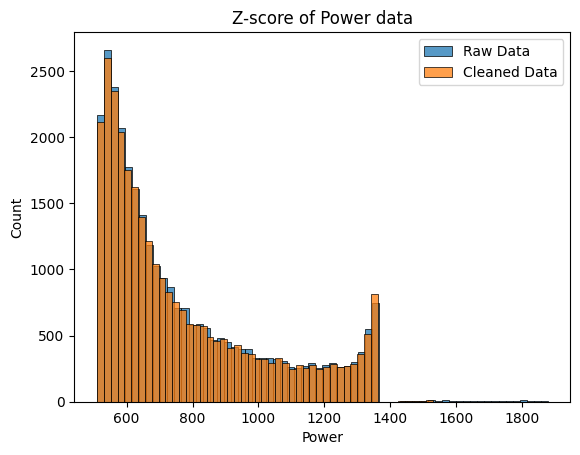

In [27]:
sns.histplot(y_train, label="Raw Data")
sns.histplot(y_train_clean.values.ravel(), label="Cleaned Data")
plt.legend()
# plt.ylim(0, 50)
plt.title("Z-score of Power data")

Let's train the model on cleaned data.

In [28]:
params = {"n_estimators": 100, "random_state": SEED, "n_jobs": -1}

eval_results = eval_model(x_train, y_train_clean, x_test, y_test, 3, "RF", params)
eval_results

{'cv_mae': 65.13,
 'cv_rmse': 95.47,
 'cv_mape': 7.65,
 'test_mae': 71.89,
 'test_rmse': 120.93,
 'test_mape': 9.29,
 'y_pred_test': array([563.039, 623.78 , 554.354, ..., 744.973, 597.144, 689.436]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [29]:
# Previous RF metrics
# 'cv_mae': 70.0,
#  'cv_rmse': 113.31,
#  'cv_mape': 8.15,
#  'test_mae': 74.51,
#  'test_rmse': 122.62,
#  'test_mape': 9.76,

We see that we reduced the Cross-Validation errors a lot which makes sense because we don't compute the errors for the outliers now.

**But what is also important to notice is that we reduced the test errors qute a lot EVEN THOUGH we haven't removed the outliers there.**

So, removing outliers that cover 0.39% of the data is crucial and can produce better results that endless model tuning.

Now, let's check outliers in features.

## Outliers removal in features

In [31]:
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
df = df[df["Power"] > 20].copy()

In [32]:
(x_train, y_train, x_test, y_test) = get_datasets(df, "Power")

Let's first plot the raw features data.

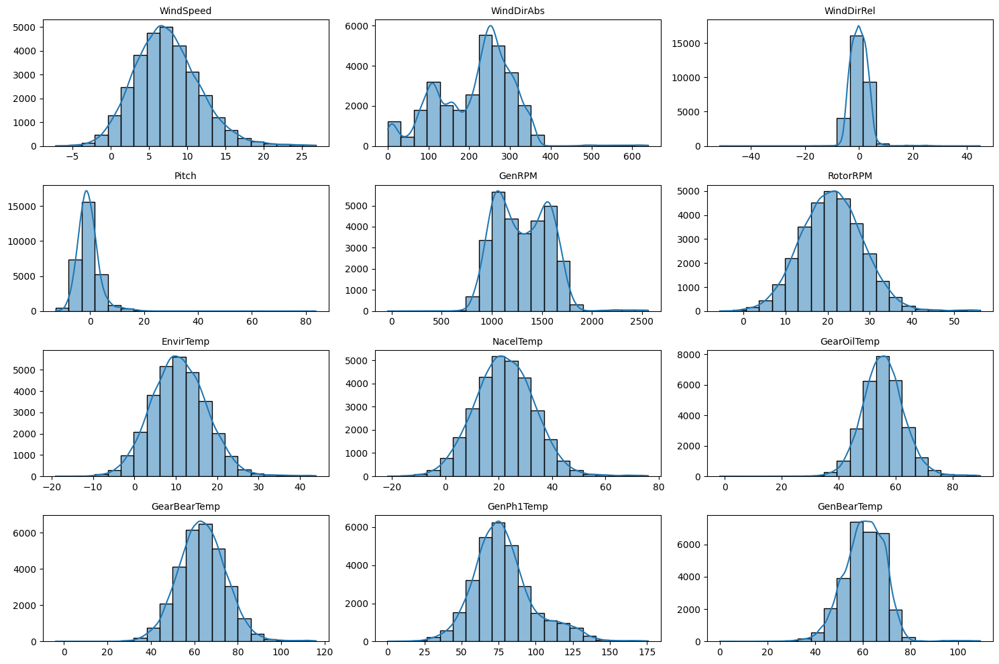

In [33]:
n_cols = 3
n_rows = int(np.ceil(len(x_train.columns) / n_cols))

plt.figure(figsize=(15, 10))

for i, col in enumerate(x_train.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(x_train[col].dropna(), bins=20, kde=True)
    plt.title(col, fontsize=10)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()

We see that for most of the parameters, we have long tails which indicate outlying values.

In [34]:
# Remove outliers in the target
y_train_clean, _ = remove_outliers_zscore(
    pd.DataFrame(y_train), nan_treatment="ffill", threshold=3
)

Power: 117 replaced
TOTAL replaced: 117


In [35]:
# Remove outliers in features
x_train_clean, z_score_stats = remove_outliers_zscore(
    x_train, nan_treatment="ffill", threshold=3
)

WindSpeed: 226 replaced
WindDirAbs: 150 replaced
WindDirRel: 204 replaced
Pitch: 393 replaced
GenRPM: 163 replaced
RotorRPM: 170 replaced
EnvirTemp: 194 replaced
NacelTemp: 198 replaced
GearOilTemp: 245 replaced
GearBearTemp: 196 replaced
GenPh1Temp: 201 replaced
GenBearTemp: 237 replaced
TOTAL replaced: 2577


Since we are cleaning features, it's essential to use the same cleaning on both training and test sets.

In this particular filter, we save the mean and std statistics from the training set and then apply them on the test set.

**IMPORTANT: If we do NOT do that, we introduce data leackage because we would use the infromation from the future on the test set.**

So, we use **z_score_stats** computed o the training set to clean the test set.

In [36]:
# Demonstrate drop as well
x_test_clean, _ = remove_outliers_zscore(
    x_test, nan_treatment="ffill", threshold=3, stats=z_score_stats
)

WindSpeed: 151 replaced
WindDirAbs: 149 replaced
WindDirRel: 264 replaced
Pitch: 192 replaced
GenRPM: 159 replaced
RotorRPM: 192 replaced
EnvirTemp: 216 replaced
NacelTemp: 196 replaced
GearOilTemp: 230 replaced
GearBearTemp: 200 replaced
GenPh1Temp: 180 replaced
GenBearTemp: 245 replaced
TOTAL replaced: 2374


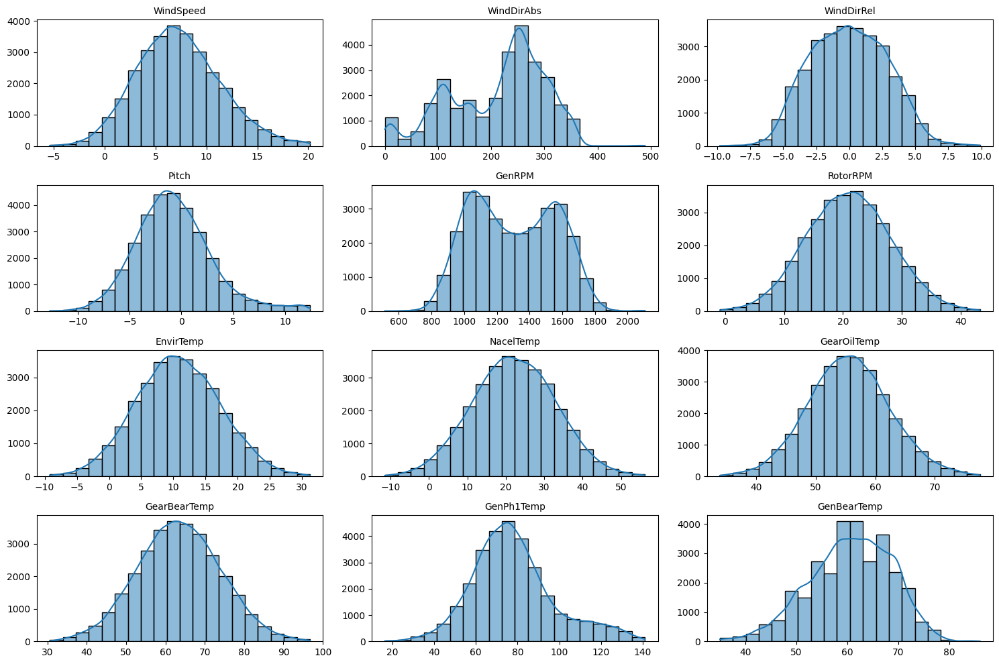

In [37]:
n_cols = 3
n_rows = int(np.ceil(len(x_train.columns) / n_cols))

plt.figure(figsize=(15, 10))

for i, col in enumerate(x_train.columns, 1):
    plt.subplot(n_rows, n_cols, i)
    sns.histplot(x_train_clean[col].dropna(), bins=20, kde=True)
    plt.title(col, fontsize=10)
    plt.xlabel("")
    plt.ylabel("")

plt.tight_layout()

We see that we removed the outliers quite well because we do not see long tails.

In [38]:
params = {"n_estimators": 100, "random_state": SEED, "n_jobs": -1}

eval_results = eval_model(
    x_train_clean, y_train_clean, x_test_clean, y_test, 3, "RF", params
)
eval_results

{'cv_mae': 64.69,
 'cv_rmse': 94.61,
 'cv_mape': 7.62,
 'test_mae': 71.75,
 'test_rmse': 121.05,
 'test_mape': 9.27,
 'y_pred_test': array([572.953     , 614.408     , 553.874     , ..., 765.87563284,
        600.498     , 696.108     ]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [39]:
# Previous errors
# 'cv_mae': 65.02,
#  'cv_rmse': 95.33,
#  'cv_mape': 7.64,
#  'test_mae': 71.88,
#  'test_rmse': 120.91,
#  'test_mape': 9.29,

We see that the error is not influenced much in this case.

This is true for THIS PARTICULAR dataset.

However, this might NOT be true for many-many other datasets.

So, removing outliers in features IN ADDITION to the target is a MUST step to check in any time series-based analysis.

In this case, we WILL implement outlier removal in features as well, so you know how to implement this in production and then later in your work projects.

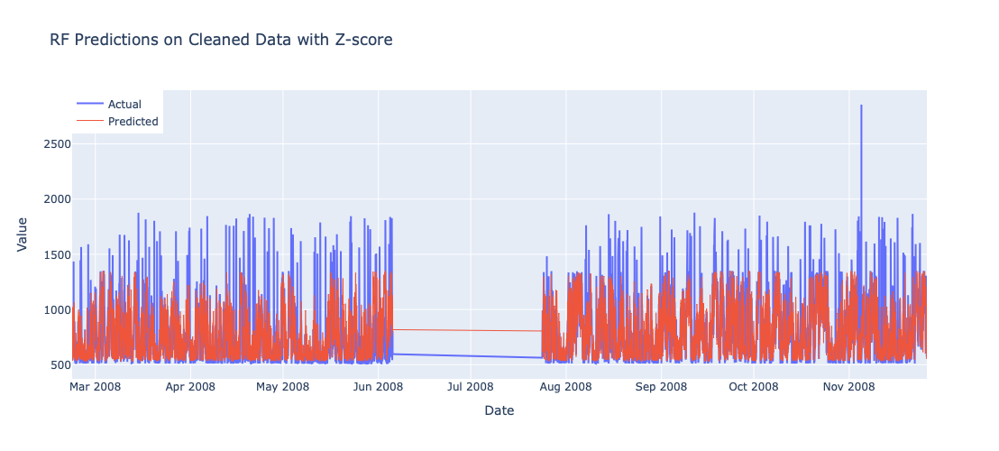

In [40]:
plot_predictions(
    y_test, eval_results["y_pred_test"], "RF Predictions on Cleaned Data with Z-score"
)

### Outlier dropping vs ffilling

Pure data dropping is usually not good because it's harder to maintain in production (making sure that the indicies are aligned between X (fefatures) and y (target)) and we lose information.

Unless we get a very good improvement, it's better to stick with some filling or interpolation options.

On the other hand, forward filling might not be an ideal option because it create data that in realily (most likely) never existed.

You can fill with other options but:

1. It's gives headache in production
2. Again, you will create data that never existed.

For now, let's just make forward fill because then we don't need to make sure that X and y indicies match (twice!).

However, it's a good execise to test dropping the indicies for the outliying values and see how the model behaves, so feel free!

# Analysis of RF predictions

Ok, now as we have built the first robust baseline, we can start analyzing the predictions in more detail.

**It's time to see if your hypothesis about ML model prediction error that will detect anomaly is true!**

Let's prepare the function that plots the actual values versus ML model predictions.

Also, since our dataset is very noisy and we don't clean (for now) the test set target value, the error value can be noisy as well.

So, we introduce the median rolling to see the trends better.

In [41]:
def plot_errors(
    x_true: pd.DataFrame,
    y_true: pd.Series | pd.DataFrame,
    y_pred: np.ndarray | list,
    error: Literal["mae", "mape", "rmse"],
    error_threshold: float,
    rolling_window: int,
) -> None:
    """
    Plot prediction errors with detected anomalies and threshold lines.

    Parameters
    ----------
    x_true : pd.DataFrame
        Original input data (with datetime index).
    y_true : pd.Series or pd.DataFrame
        True target values.
    y_pred : array-like
        Predicted target values.
    error : {"mae", "mape"}
        Type of error to visualize.
    error_threshold : float
        Threshold above which points are flagged as anomalies.
    rolling_window: int
        Rollin window for the error rolling aggregation
    """

    # Create a DataFrame with true values and compute the error
    y_test_err = pd.DataFrame(y_true)
    if error == "mae":
        y_test_err["Error"] = abs(y_test_err["Power"] - y_pred)
    elif error == "rmse":
        y_test_err["Error"] = np.sqrt((y_test_err["Power"] - y_pred) ** 2)
    elif error == "mape":
        y_test_err["Error"] = (
            abs(y_test_err["Power"] - y_pred) / y_test_err["Power"] * 100
        )

    # Ensure both y_test_err and x_true have datetime indices
    y_test_err.index = pd.to_datetime(y_test_err.index)
    x_true.index = pd.to_datetime(x_true.index)

    # Initialize Plotly figure
    fig = go.Figure()

    # Plot the error over time
    fig.add_trace(
        go.Scatter(
            x=y_test_err.index,
            y=y_test_err["Error"].values,
            mode="lines",
            name="Error",
            line=dict(width=2),
        )
    )

    # Add horizontal line for static 95th percentile threshold
    fig.add_hline(
        y=error_threshold,
        line_color="black",
        annotation_text="Upper Threshold",
        annotation_position="bottom right",
    )

    # Plot rolling median error for smoothed trend
    fig.add_trace(
        go.Scatter(
            x=y_test_err.index,
            y=y_test_err["Error"].rolling(rolling_window).median(),
            mode="lines",
            name="Rolling Median Error",
            line=dict(width=2),
        )
    )

    # Configure layout settings
    fig.update_layout(
        title="Prediction Error and Anomaly Detection",
        xaxis_title="Date",
        yaxis_title="Error",
        legend=dict(x=0, y=1),
        height=500,
        template="plotly_white",
    )

    fig.show()

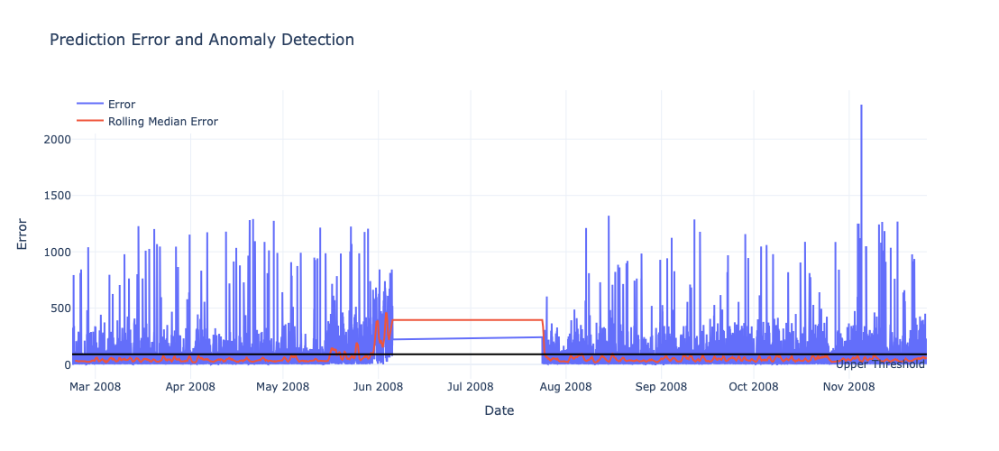

In [42]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mae",
    error_threshold=90,
    rolling_window=144,
)  # 72, 144

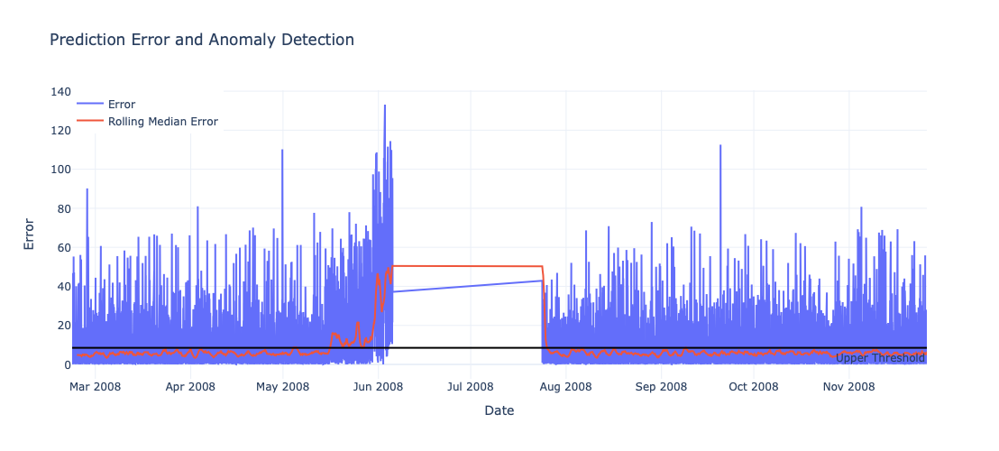

In [43]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mape",
    error_threshold=8.5,
    rolling_window=228,
)  # 72, 144

This looks great!

Now we actually see that the error noticeably rises before the downtime.

What is great, it starts doing so about May 16-17 which is way earlier that with Mahalanobis Distance Detection we did previous (it detected anomaly about May 30).

Let's also see what does raw error and the rolling error looks like.

In [44]:
mae_error = abs(y_test - eval_results["y_pred_test"])
mae_error_rol = mae_error.rolling(144).median()

In [45]:
mape_error = abs(y_test - eval_results["y_pred_test"]) / y_test * 100
mape_error_rol = mape_error.rolling(144).median()

(0.0, 30.0)

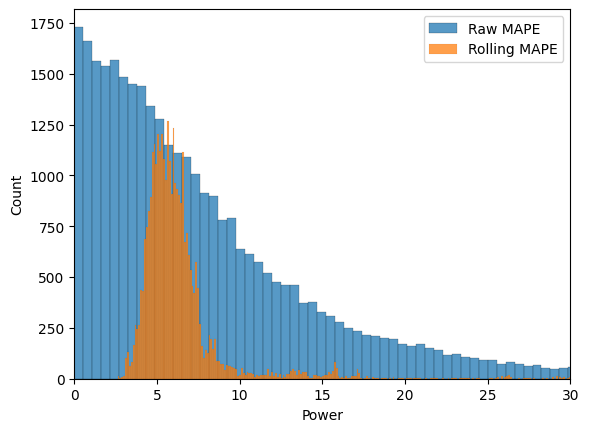

In [46]:
sns.histplot(mape_error, label="Raw MAPE")
sns.histplot(mape_error_rol, label="Rolling MAPE")
plt.legend()
plt.xlim(0, 30)

We see that the rolling value is much more stable. 

It's also easier to select a threshold above which we can consider the errors to show anomalies.

Generally, we can have 2 options:
1. Fix the threshold value.
2. Compute it as a quantile.

Let's try to see the possible quantile.

In [47]:
np.quantile(mape_error_rol.dropna(), 0.91)

9.094922373080662

Potentially, we can use quantile in the range [0.93-0.95].

For simplicity, we can keep just the value and then switch if we want to.

**Preliminary Conclusions**

We can see that we can identify the anomaly region about 19-20 days in advance which is quite good.

The number of days to shutdown (Time-to-Failure) is THE metric we need to optimize.

For experiments, we can still for now leave Cross Validation ML metrics with the assumption that the better metrics, the more stable and accurate predictions of the business metrics are.

Let's iterate using the ML metrics and for some promising models compute the Time-to-Failure metric.

# Feature Engineering: Lagged features including Target

Before computing features, it's highly recommended that we remove the outliers BEFORE it.

Otherwise, we would need to remove outliers twice which can introduce even more noise to the data.

In [48]:
# Read again for reproducibility
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df = df[df["Power"] > 20].copy()
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
# First, we need to get the training dataset
df_train = df[:30_000]
df_test = df[30_000:]

In [49]:
# Note that for the train set, we clean features + target
df_clean_train, z_score_stats = remove_outliers_zscore(
    df_train, threshold=3, nan_treatment="ffill"
)

WindSpeed: 226 replaced
WindDirAbs: 150 replaced
WindDirRel: 204 replaced
Power: 117 replaced
Pitch: 393 replaced
GenRPM: 163 replaced
RotorRPM: 170 replaced
EnvirTemp: 194 replaced
NacelTemp: 198 replaced
GearOilTemp: 245 replaced
GearBearTemp: 196 replaced
GenPh1Temp: 201 replaced
GenBearTemp: 237 replaced
TOTAL replaced: 2694


In [50]:
# Cleaning the features in the test set
features = [col for col in df.columns if col not in ["Power"]]
x_clean_test, _ = remove_outliers_zscore(
    df_test[features], threshold=3, nan_treatment="ffill", stats=z_score_stats
)

WindSpeed: 151 replaced
WindDirAbs: 149 replaced
WindDirRel: 264 replaced
Pitch: 192 replaced
GenRPM: 159 replaced
RotorRPM: 192 replaced
EnvirTemp: 216 replaced
NacelTemp: 196 replaced
GearOilTemp: 230 replaced
GearBearTemp: 200 replaced
GenPh1Temp: 180 replaced
GenBearTemp: 245 replaced
TOTAL replaced: 2374


In [51]:
df_clean_test = pd.concat([x_clean_test, df_test["Power"]], axis=1)

Now let's add lag features

In [52]:
def add_lag_features(
    df: pd.DataFrame, columns: list[str] = None, lags: list[int] = [1], drop_na=True
):
    """
    Add lag features to DataFrame.

    Parameters:
    - df: DataFrame
    - columns: list of column names (default: all numeric)
    - lags: int or list of lag periods (default: 1)
    - drop_na: bool, drop NaN rows (default: True)

    Returns: DataFrame with lag features
    """
    df_result = df.copy()

    # Create lag features
    for col in columns:
        for lag in lags:
            df_result[f"{col}_lag{lag}"] = df_result[col].shift(lag)

    if drop_na:
        return df_result.dropna()
    else:
        return df_result.bfill()  # Backward fill NaNs

In [53]:
# Adding lagged features
df_train_feat = add_lag_features(
    df_clean_train, columns=["Power", "GenRPM"], lags=[1, 2, 3], drop_na=False
)
x_test_feat = add_lag_features(
    df_clean_test, columns=["Power", "GenRPM"], lags=[1, 2, 3], drop_na=False
)

In [54]:
x_test_feat.head(3)

,WindSpeed,WindDirAbs,WindDirRel,Pitch,GenRPM,RotorRPM,EnvirTemp,NacelTemp,GearOilTemp,GearBearTemp,GenPh1Temp,GenBearTemp,Power,Power_lag1,Power_lag2,Power_lag3,GenRPM_lag1,GenRPM_lag2,GenRPM_lag3
Timestamps,,,,,,,,,,,,,,,,,,,
2008-02-22 11:10:00,-0.741716,276.1,-4.0,0.255242,1072.834680,10.982573,7.390700,8.295011,52.511862,70.667622,83.549031,75.0,567.7,567.7,567.7,567.7,1072.834680,1072.83468,1072.83468
2008-02-22 11:20:00,1.935043,273.0,-0.6,-2.235587,1205.902957,22.868729,18.081372,31.785403,46.913939,67.091015,78.911070,75.0,565.7,567.7,567.7,567.7,1072.834680,1072.83468,1072.83468
2008-02-22 11:30:00,3.338915,279.4,1.1,3.705763,940.470489,13.460942,17.575849,24.438282,51.109446,51.174857,92.277061,75.0,566.7,565.7,567.7,567.7,1205.902957,1072.83468,1072.83468


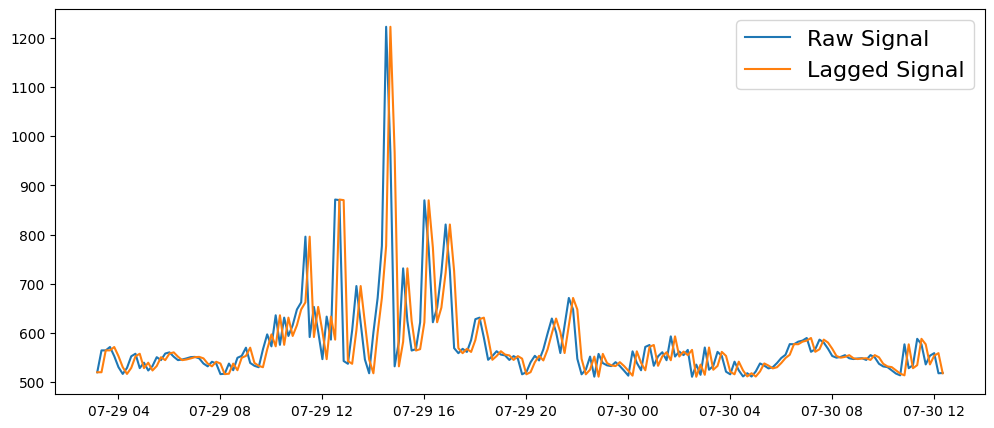

In [55]:
plt.figure(figsize=(12, 5))
plt.plot(df_clean_train["Power"][:200], label="Raw Signal")
plt.plot(df_train_feat["Power_lag1"][:200], label="Lagged Signal")
plt.legend(fontsize=16)

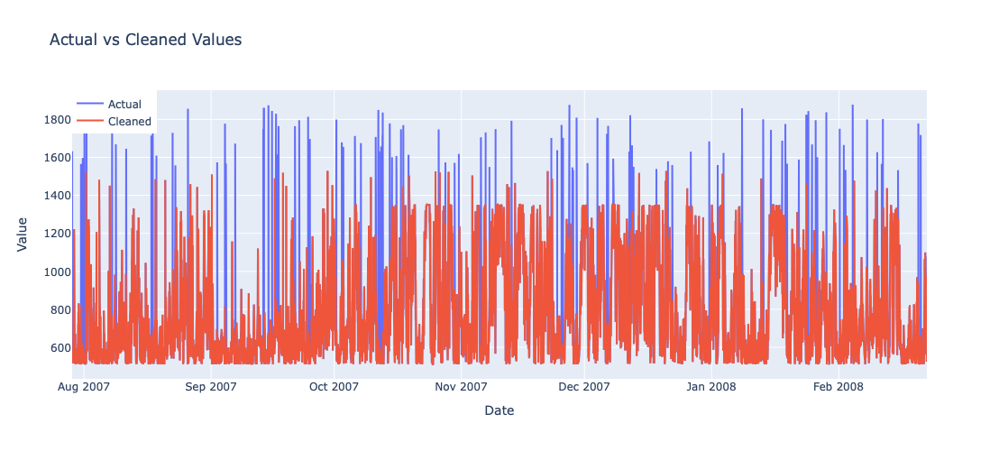

In [56]:
# Assume y_test and y_pred are pandas Series with a datetime index
fig = go.Figure()

# Add actual values
fig.add_trace(
    go.Scatter(
        x=x_train.index,
        y=df_train["Power"].values,
        mode="lines",
        name="Actual",
        line=dict(width=2),
    )
)

# Add predicted values
fig.add_trace(
    go.Scatter(
        x=x_train.index,
        y=df_clean_train["Power"].values,
        mode="lines",
        name="Cleaned",
        line=dict(width=2),
    )
)

# Customize layout
fig.update_layout(
    title="Actual vs Cleaned Values",
    xaxis_title="Date",
    yaxis_title="Value",
    legend=dict(x=0, y=1),
    height=500,
)

fig.show()

It seems that the outliers are cleaned quite well.

However, let's look at the cleaned data alone.

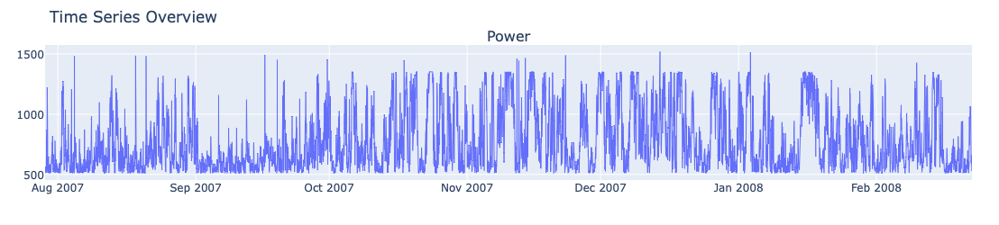

In [57]:
plot_time_series(df_clean_train, ["Power"], step=2)

Here, we can still see the outliers.

Even though the outliers are similar in nature, z-score filter cannot capture it.

This is important because we add lagged features, so if the data is not cleaned well, we create additional outlying values to the training data.

We will consider this fact when we do more in-depth cleaning.

**Note how we add the features only AFTER the data split into the train and test to:**
1. Avoid data leakage into the future.
2. Slowly preparing the code and flow that we will then put to the production pipelines.

In [58]:
features = [
    col for col in df_train_feat.columns if col != "Power"
]  # Note that we keep Power_lagged features
# Train
x_clean_train = df_train_feat[features].copy()
y_clean_train = df_train_feat["Power"].copy()
# Test
x_clean_test = x_test_feat[features].copy()
y_test = df_test["Power"].copy()

In [59]:
params = {"n_estimators": 100, "random_state": SEED, "n_jobs": -1}

eval_results = eval_model(
    x_clean_train, y_clean_train, x_clean_test, y_test, 3, "RF", params
)
eval_results

{'cv_mae': 42.49,
 'cv_rmse': 64.76,
 'cv_mape': 5.06,
 'test_mae': 45.68,
 'test_rmse': 89.1,
 'test_mape': 5.71,
 'y_pred_test': array([564.716, 587.613, 551.967, ..., 688.246, 637.41 , 683.967]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [ ]:
# Previous metrics
# 'cv_mae': 64.69,
#  'cv_rmse': 94.61,
#  'cv_mape': 7.62,
#  'test_mae': 71.75,
#  'test_rmse': 121.05,
#  'test_mape': 9.27,

Nice! We see that we significanlty the errors.

Let's see now how this looks in terms of Time to Failure.

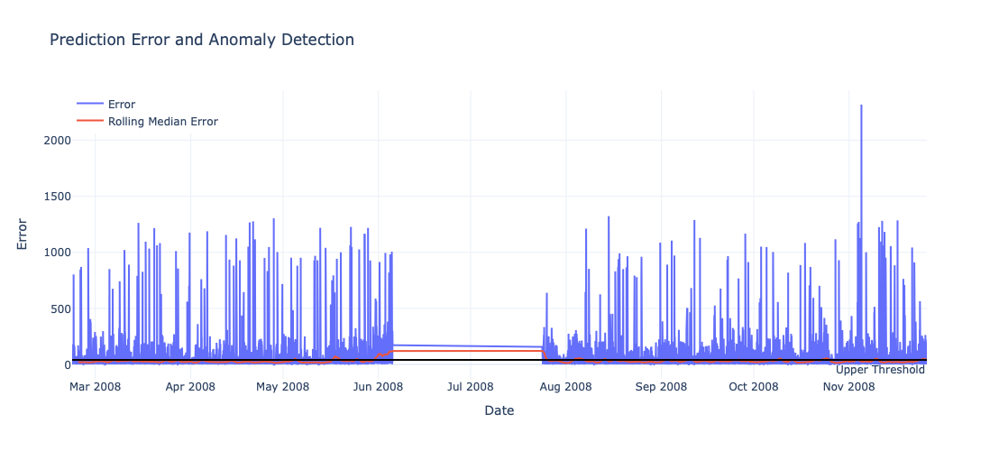

In [60]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mae",
    error_threshold=40,
    rolling_window=288,
)

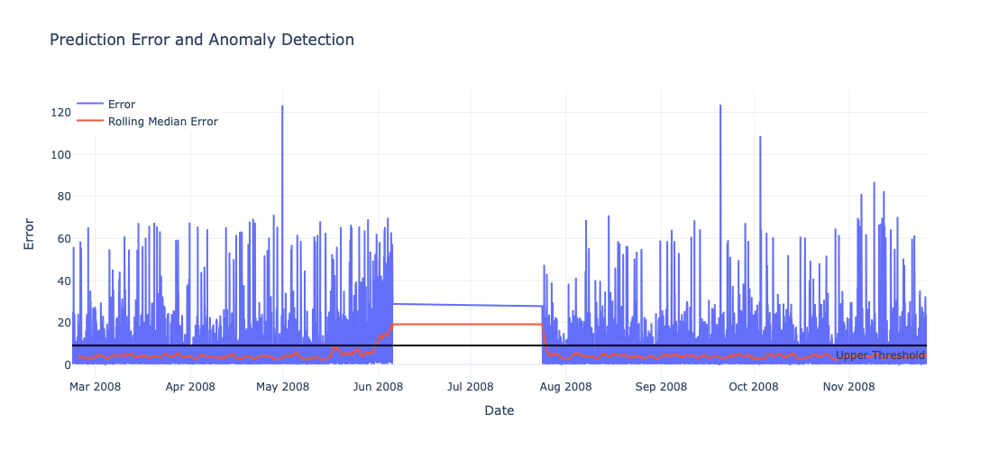

In [61]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mape",
    error_threshold=9,
    rolling_window=288,
)

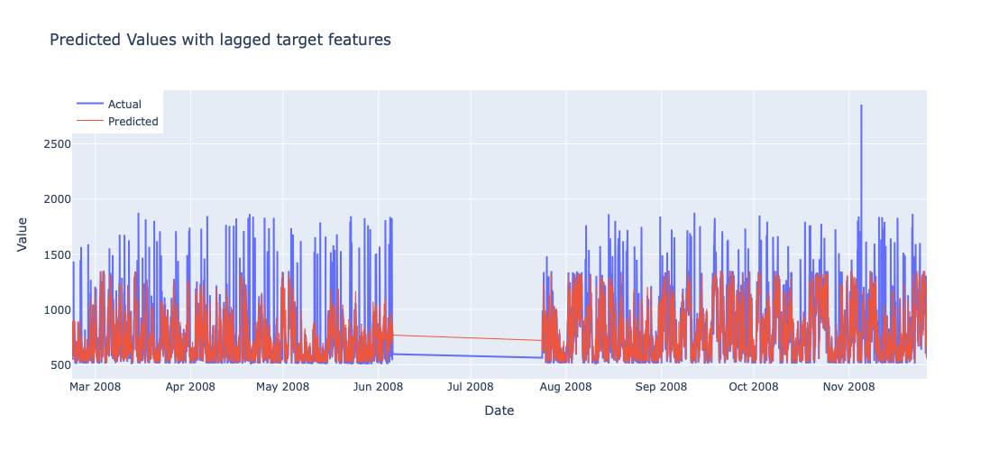

In [62]:
plot_predictions(
    y_test, eval_results["y_pred_test"], "Predicted Values with lagged target features"
)

Very often adding lagged features help a lot.

In this case, it also helped to reduce the error of the model.

**However, in our case, even though the predictions are better, the problem is that we start including the "degraded" parameter into the model as the feature.**

This results in the fact that the prediction becomes more unstable and HARDER to see the anomaly region and distinguish it from the normal region.

All this can make it confusing to interpret the model behavior.

Let's NOT include Power as a feature and instead include some other parameters.

**THIS SHOWS AN EXAMPLE WHEN BETTER ML METRICS DO NOT RESULT IN BETTER BUSINESS METRICS.**

# Feature Engineering: Lagged features WITHOUT Target

In [63]:
# Read again for reproducibility
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df = df[df["Power"] > 20].copy()
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
# First, we need to get the training dataset
df_train = df[:30_000]
df_test = df[30_000:]

In [64]:
df_clean_train, z_score_stats = remove_outliers_zscore(
    df_train, threshold=3, nan_treatment="ffill"
)

WindSpeed: 226 replaced
WindDirAbs: 150 replaced
WindDirRel: 204 replaced
Power: 117 replaced
Pitch: 393 replaced
GenRPM: 163 replaced
RotorRPM: 170 replaced
EnvirTemp: 194 replaced
NacelTemp: 198 replaced
GearOilTemp: 245 replaced
GearBearTemp: 196 replaced
GenPh1Temp: 201 replaced
GenBearTemp: 237 replaced
TOTAL replaced: 2694


In [65]:
# Cleaning the features in the test set
features = [col for col in df.columns if col not in ["Power"]]
x_clean_test, _ = remove_outliers_zscore(
    df_test[features], threshold=3, nan_treatment="ffill", stats=z_score_stats
)

WindSpeed: 151 replaced
WindDirAbs: 149 replaced
WindDirRel: 264 replaced
Pitch: 192 replaced
GenRPM: 159 replaced
RotorRPM: 192 replaced
EnvirTemp: 216 replaced
NacelTemp: 196 replaced
GearOilTemp: 230 replaced
GearBearTemp: 200 replaced
GenPh1Temp: 180 replaced
GenBearTemp: 245 replaced
TOTAL replaced: 2374


In [66]:
df_clean_test = pd.concat([x_clean_test, df_test["Power"]], axis=1)

In [67]:
# Adding lagged features
df_train_feat = add_lag_features(
    df_clean_train, columns=["GenRPM", "GenPh1Temp"], lags=[1, 2, 3], drop_na=False
)
x_test_feat = add_lag_features(
    df_clean_test, columns=["GenRPM", "GenPh1Temp"], lags=[1, 2, 3], drop_na=False
)

In [68]:
features = [col for col in df_train_feat.columns if col != "Power"]
# Train
x_clean_train = df_train_feat[features].copy()
y_clean_train = df_train_feat["Power"].copy()

# Test
x_clean_test = x_test_feat[features].copy()
y_test = df_test["Power"].copy()

In [69]:
params = {"n_estimators": 100, "random_state": SEED, "n_jobs": -1}

eval_results = eval_model(
    x_clean_train, y_clean_train, x_clean_test, y_test, 3, "RF", params
)
eval_results

{'cv_mae': 56.27,
 'cv_rmse': 82.77,
 'cv_mape': 6.64,
 'test_mae': 65.34,
 'test_rmse': 115.1,
 'test_mape': 8.39,
 'y_pred_test': array([554.986, 587.801, 558.57 , ..., 701.758, 626.954, 663.728]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [ ]:
# Previous metrics
# 'cv_mae': 64.69,
#  'cv_rmse': 94.61,
#  'cv_mape': 7.62,
#  'test_mae': 71.75,
#  'test_rmse': 121.05,
#  'test_mape': 9.27,

Cool! We see that we still reduced the error but hopefully we have NOT deteriorated the anomaly class close to the downtime.

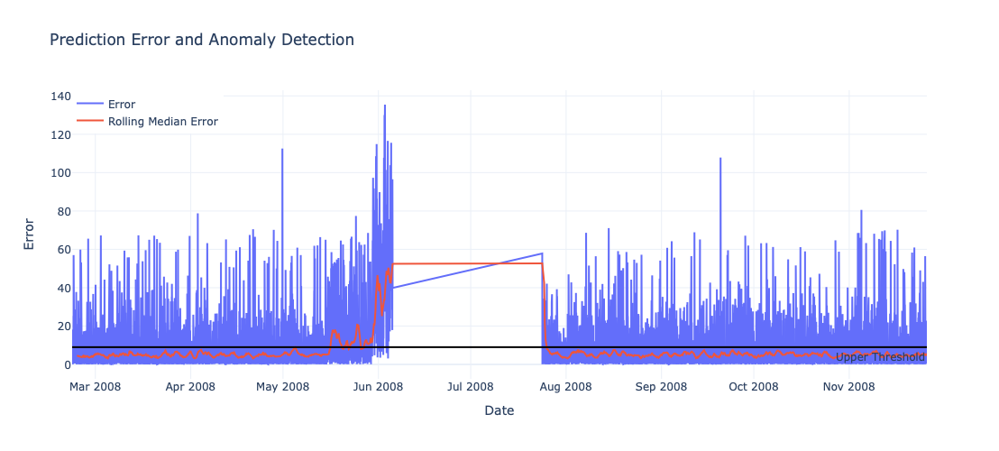

In [70]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mape",
    error_threshold=9,
    rolling_window=228,
)

**We see tht we can still clearly distiguish the anomaly class AND we reduced the cross-validation error.**

It seems that this is a perfect mix.

# Statistical rolling features

Now, let's add basic statistical features

In [71]:
def add_rolling_features(
    df: pd.DataFrame,
    columns: list[str],
    window_sizes: list[int] = [7],
    stats: list[str] = ["mean", "median"],
    drop_na=True,
):
    """
    Add rolling features to DataFrame.

    Parameters:
    - df: DataFrame
    - columns: list of column names
    - window_sizes: int or list of window sizes (default: 7)
    - stats: list of statistics ['mean', 'median', 'std', 'min', 'max', 'skew', 'kurt']
    - drop_na: bool, drop NaN rows (default: True)

    Returns: DataFrame with rolling features
    """
    df_result = df.copy()

    # Create rolling features
    for col in columns:
        for window in window_sizes:
            rolling = df_result[col].rolling(window)

            for stat in stats:
                if stat == "mean":
                    df_result[f"{col}_roll{window}_mean"] = rolling.mean()
                elif stat == "median":
                    df_result[f"{col}_roll{window}_median"] = rolling.median()
                elif stat == "std":
                    df_result[f"{col}_roll{window}_std"] = rolling.std()
                elif stat == "min":
                    df_result[f"{col}_roll{window}_min"] = rolling.min()
                elif stat == "max":
                    df_result[f"{col}_roll{window}_max"] = rolling.max()
                elif stat == "skew":
                    df_result[f"{col}_roll{window}_skew"] = rolling.skew()
                elif stat == "kurt":
                    df_result[f"{col}_roll{window}_kurt"] = rolling.kurt()
    if drop_na:
        return df_result.dropna()
    else:
        return df_result.bfill()  # Backward fill NaNs

In [72]:
# Read again for reproducibility
df = pd.read_parquet("../data/01_raw/df_train_test.parquet")
df = df[df["Power"] > 20].copy()
df.index = pd.to_datetime(df["Timestamps"])
df.drop(columns=["Timestamps"], inplace=True)
# First, we need to get the training dataset
df_train = df[:30_000]
df_test = df[30_000:]

In [73]:
df_clean_train, z_score_stats = remove_outliers_zscore(
    df_train, threshold=3, nan_treatment="ffill"
)
features = [col for col in df.columns if col not in ["Power"]]
x_clean_test, _ = remove_outliers_zscore(
    df_test[features], threshold=3, nan_treatment="ffill", stats=z_score_stats
)
df_clean_test = pd.concat([x_clean_test, df_test["Power"]], axis=1)

WindSpeed: 226 replaced
WindDirAbs: 150 replaced
WindDirRel: 204 replaced
Power: 117 replaced
Pitch: 393 replaced
GenRPM: 163 replaced
RotorRPM: 170 replaced
EnvirTemp: 194 replaced
NacelTemp: 198 replaced
GearOilTemp: 245 replaced
GearBearTemp: 196 replaced
GenPh1Temp: 201 replaced
GenBearTemp: 237 replaced
TOTAL replaced: 2694
WindSpeed: 151 replaced
WindDirAbs: 149 replaced
WindDirRel: 264 replaced
Pitch: 192 replaced
GenRPM: 159 replaced
RotorRPM: 192 replaced
EnvirTemp: 216 replaced
NacelTemp: 196 replaced
GearOilTemp: 230 replaced
GearBearTemp: 200 replaced
GenPh1Temp: 180 replaced
GenBearTemp: 245 replaced
TOTAL replaced: 2374


In [74]:
# Adding lagged features
df_clean_train = add_lag_features(
    df_clean_train, columns=["GenRPM", "GenPh1Temp"], lags=[1, 2, 3], drop_na=False
)
df_clean_test = add_lag_features(
    df_clean_test, columns=["GenRPM", "GenPh1Temp"], lags=[1, 2, 3], drop_na=False
)

Let's add some (not much) lags for the main features only as well as some statistics.

In [75]:
df_train_feat = add_rolling_features(
    df_clean_train,
    window_sizes=[5, 10, 15],
    columns=["GenRPM", "WindSpeed", "GenPh1Temp"],
    stats=["median", "std", "min", "max"],
    drop_na=False,
)

In [76]:
x_test_feat = add_rolling_features(
    df_clean_test,
    window_sizes=[5, 10, 15],
    columns=["GenRPM", "WindSpeed", "GenPh1Temp"],
    stats=["median", "std", "min", "max"],
    drop_na=False,
)

In [77]:
features = [col for col in df_train_feat.columns if col != "Power"]
# Train
x_clean_train = df_train_feat[features].copy()
y_clean_train = df_train_feat["Power"].copy()

# Test
x_clean_test = x_test_feat[features].copy()
y_test = df_test["Power"].copy()

In [78]:
eval_results = eval_model(
    x_clean_train, y_clean_train, x_clean_test, y_test, 3, "RF", params
)
eval_results

{'cv_mae': 55.21,
 'cv_rmse': 80.76,
 'cv_mape': 6.58,
 'test_mae': 64.46,
 'test_rmse': 114.07,
 'test_mape': 8.3,
 'y_pred_test': array([544.802, 548.674, 541.029, ..., 702.679, 622.681, 669.761]),
 'model': RandomForestRegressor(n_jobs=-1, random_state=42)}

In [ ]:
# Previous metrics
# 'cv_mae': 56.27,
#  'cv_rmse': 82.77,
#  'cv_mape': 6.64,
#  'test_mae': 65.34,
#  'test_rmse': 115.1,
#  'test_mape': 8.39,

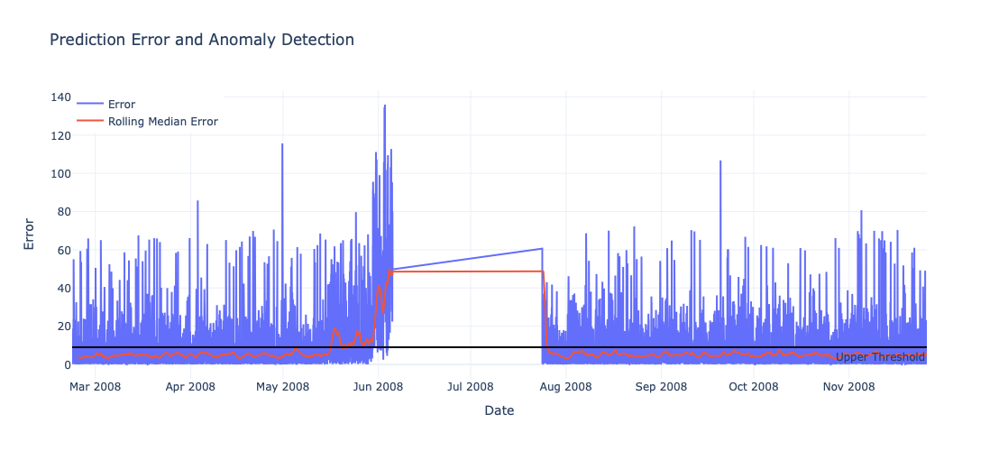

In [79]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mape",
    error_threshold=9,
    rolling_window=288,
)

We see that overall, it seems we improved the model performance.

This can potentially confirm the fact that the noise in features make our model performance worse and when adding rolling features, we reduce this noise and improve the model performance.

# Treating Regression Error as Anomaly

Let's now prepare some formal calculations of the ML Model Error <-> anomaly detection.

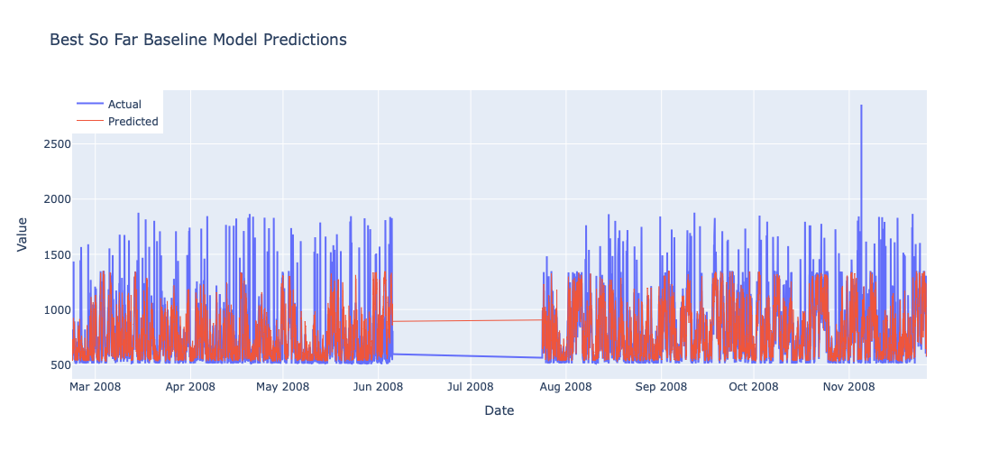

In [80]:
plot_predictions(
    y_test, eval_results["y_pred_test"], "Best So Far Baseline Model Predictions"
)

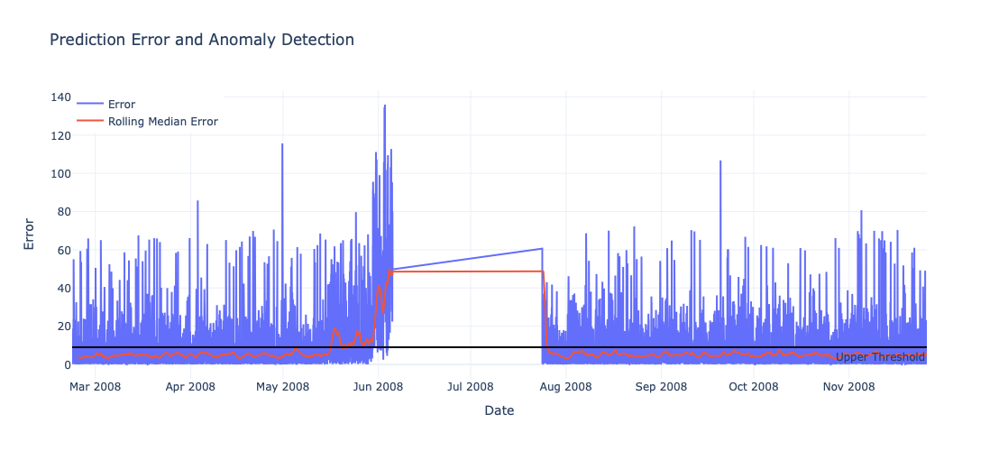

In [81]:
plot_errors(
    x_test,
    y_test,
    eval_results["y_pred_test"],
    error="mape",
    error_threshold=9,
    rolling_window=288,
)

In [82]:
mape_error = abs(y_test - eval_results["y_pred_test"]) / y_test * 100
mape_error_rol = mape_error.rolling(288).median()

Text(0.5, 1.0, 'MAPE Rolling Error')

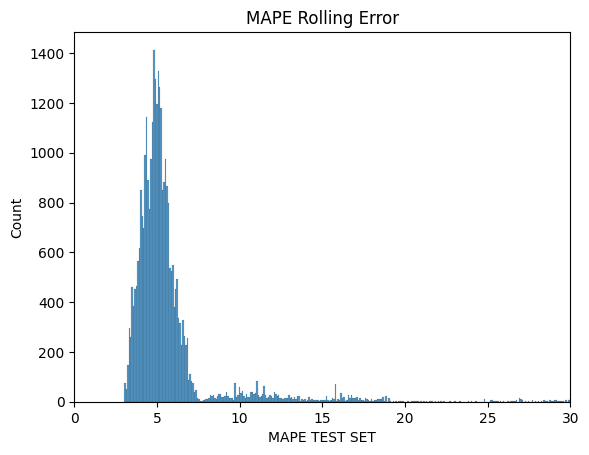

In [83]:
sns.histplot(mape_error_rol)
plt.xlim(0, 30)
plt.xlabel("MAPE TEST SET")
plt.title("MAPE Rolling Error")

In [84]:
np.quantile(mape_error_rol.dropna(), 0.91)

9.451369780549893

### Let's compute how much time in advance we can detect the anomaly

In [85]:
def detect_anomaly(
    y_true: np.ndarray | pd.Series,
    y_pred: np.ndarray | pd.Series,
    threshold: float,
    waiting_time: int,
    rolling_window: int,
    error_type: Literal["raw", "rolling"] = "raw",
) -> np.ndarray:
    """
    Detect anomalies based on prediction error exceeding a threshold.
    Optionally applies a rolling-median smoothing to detect slow deviations.
    Requires a minimum number of consecutive violations (waiting_time)
    before confirming an anomaly.

    Parameters
    ----------
    y_true : array-like
        Ground-truth target values.
    y_pred : array-like
        Model predictions.
    threshold : float
        Error value above which a point is considered suspicious.
    waiting_time : int
        Number of consecutive threshold violations needed to flag anomaly.
    rolling_window : int
        Window size for rolling-median smoothing (used when error_type='rolling').
    error_type : {'raw','rolling'}, default='raw'
        - 'raw'     : use absolute error directly
        - 'rolling' : use rolling median of absolute error to detect slow drift

    Returns
    -------
    anomalies : np.ndarray of bool
        Boolean array marking anomaly positions.
    """

    # absolute error
    error = np.abs(np.asarray(y_true) - np.asarray(y_pred)) / np.asarray(y_true) * 100

    if error_type == "rolling":
        # rolling median (slow drift detection)
        error = (
            pd.Series(error).rolling(rolling_window, min_periods=1).median().to_numpy()
        )

    above = error > threshold
    anomalies = np.zeros_like(above, dtype=bool)

    # consecutive violations
    count = 0
    for i, flag in enumerate(above):
        count = count + 1 if flag else 0
        if count >= waiting_time:
            anomalies[i] = True

    return anomalies

In [86]:
# let's make delay 2 days: 10 mins * 6 points * 24 = 288
anomalies = detect_anomaly(
    y_true=y_test,
    y_pred=eval_results["y_pred_test"],
    threshold=8.5,
    waiting_time=72,
    rolling_window=288,
    error_type="rolling",
)

In [87]:
def plot_prediction_with_anomalies(
    x_true: pd.DataFrame,
    y_true: pd.Series,
    y_pred: np.array,
    error: str,
    error_threshold: float,
    rolling_window: int,
    anomalies=None,
):
    """
    Plot prediction errors with detected anomalies and threshold line.

    Parameters
    ----------
    x_true : pd.DataFrame
        Original input data (with index aligned to y_true).
    y_true : pd.Series or pd.DataFrame
        True target values (must contain 'Power' column if DataFrame).
    y_pred : array-like
        Predicted target values (same length as y_true).
    error : str
        Type of error to visualize. Either 'mae' or 'mape'.
    error_threshold : float
        Static threshold value to draw as a horizontal line.
    rolling_window: int
        Rolling windown for the error
    anomalies : array-like of bool, optional
        Boolean mask (same length as y_true) where True indicates anomaly.
    """

    # --- Build y_test_err DataFrame with 'Power' + 'Error' ---

    # Ensure y_true is DataFrame with column 'Power'
    if isinstance(y_true, pd.Series):
        y_test_err = y_true.to_frame(name="Power").copy()
    else:
        y_test_err = y_true[["Power"]].copy()

    # Compute error
    if error == "mae":
        y_test_err["Error"] = (y_test_err["Power"] - y_pred).abs()
    elif error == "mape":
        y_test_err["Error"] = (
            (y_test_err["Power"] - y_pred).abs() / (y_test_err["Power"] + 1e-8) * 100
        )
    else:
        raise ValueError("error must be 'mae' or 'mape'")

    # --- Handle anomalies mask robustly ---

    if anomalies is not None:
        anomalies = np.asarray(anomalies).astype(bool)

        # Align length by trimming from the front if needed
        if len(anomalies) > len(y_test_err):
            anomalies = anomalies[-len(y_test_err) :]
        elif len(anomalies) < len(y_test_err):
            # pad with False at the beginning
            pad = len(y_test_err) - len(anomalies)
            anomalies = np.concatenate([np.zeros(pad, dtype=bool), anomalies])

        # Now lengths match exactly
        y_test_err["Anomaly"] = anomalies
    else:
        y_test_err["Anomaly"] = False

    print(f"Number of anomalies: {y_test_err['Anomaly'].sum()}")

    # --- Build figure ---

    # Compute rolling median for plotting
    rolling_median_error = (
        y_test_err["Error"].rolling(rolling_window, min_periods=1).median()
    )

    fig = go.Figure()

    # 1) Error line
    fig.add_trace(
        go.Scatter(
            x=y_test_err.index,
            y=y_test_err["Error"].values,
            mode="lines",
            name="Error",
            line=dict(width=2),
        )
    )

    # 2) Threshold line
    fig.add_hline(
        y=error_threshold,
        line_color="black",
        annotation_text="Upper Threshold",
        annotation_position="bottom right",
    )

    # 3) Rolling median error (use precomputed series)
    fig.add_trace(
        go.Scatter(
            x=y_test_err.index,
            y=rolling_median_error,
            mode="lines",
            name="Rolling Median Error",
            line=dict(width=2),
        )
    )

    # 4) Anomaly markers (slice the same rolling median series)
    anomaly_mask = y_test_err["Anomaly"]
    if anomaly_mask.any():
        fig.add_trace(
            go.Scatter(
                x=y_test_err.index[anomaly_mask],
                y=rolling_median_error[anomaly_mask],
                mode="markers",
                name="Anomaly",
                marker=dict(size=8, color="red", symbol="circle-open"),
            )
        )

    # Layout
    fig.update_layout(
        title="Prediction Error and Anomaly Detection",
        xaxis_title="Index",
        yaxis_title="Error",
        legend=dict(x=0, y=1),
        height=500,
        template="plotly_white",
    )

    fig.show()

Number of anomalies: 2822


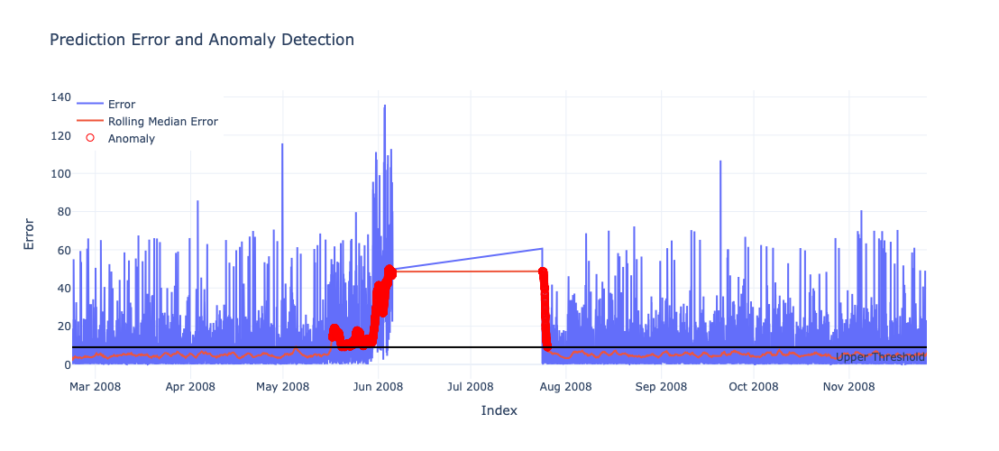

In [88]:
threshold = 9
rolling_window = 288
waiting_time = 72

anomalies = detect_anomaly(
    y_test,
    eval_results["y_pred_test"],
    threshold,
    waiting_time,
    rolling_window,
    error_type="rolling",
)

plot_prediction_with_anomalies(
    x_true=x_test,
    y_true=y_test,
    y_pred=eval_results["y_pred_test"],
    error="mape",
    error_threshold=threshold,
    rolling_window=rolling_window,
    anomalies=anomalies,
)

In [89]:
anomaly_timestamps = y_test.iloc[anomalies].index
detected_anomaly_start = anomaly_timestamps[0]
stoppage_time = pd.Timestamp("2008-06-05 15:00:00")
stoppage_time - detected_anomaly_start

Timedelta('19 days 14:40:00')

So, we see that with out baseline model, we can **ROBUSTLY** estimate the anomaly with Time-to-Failure of 19.5 days. 

# Conclusions

1. We created a good baseline model AND approach for detecting anomalies based on Random Forest Regression model.
2. We improved model performance through basic data cleaning of features and feature engineering.
3. The estimated Time-to-Failure on the test set is 19.5 days.
4. Data cleaning and basic feature engineering improves the model performance a lot comapred to the model fitted on the raw data.
5. The linear model got bad performance, so we did not proceed with it.
6. The next step is to find the best model and start registering hyperparameter tuning and model performance in MLflow for reproducibility. 